# Tutorial: per-layer error of four estimators on one network

This notebook runs four deterministic estimators of the Gaussian-input means of one public ARC white-box network
(width 1024, depth 16, bias-free ReLU, `h_l = relu(h_{l-1} @ W_l)`, `x ~ N(0, I)`) and plots the mean squared error of
each layer's predicted means against the Monte Carlo targets (1e9 samples) that ship with the dataset.

The four methods form a ladder in the order of the propagated cumulants:

| method | what is propagated | where it comes from |
|---|---|---|
| K=1 mean propagation | means and diagonal variances, neurons treated as independent | organizers' tutorial baseline, re-written in numpy below |
| K=2 covariance propagation | means and a linearised post-ReLU covariance | organizers' tutorial baseline, re-written in numpy below |
| K=3 ARC reference | mean, covariance, third cumulant (factored), radial fourth cumulant | `k3_reference.py` in this folder |
| distilled 337479 | mean, covariance, third cumulant (dense source bank), fourth cumulant (trace core + corrections) | `estimator.py` in this folder: our Phase 2 submission family without its FLOP tricks |

Requirements: `numpy matplotlib scienceplots pandas`. Nothing is downloaded: the network's weights are regenerated
bitwise from its dataset seed (the public dataset's seed protocol), and its Monte Carlo targets (64 KB) ship next to this
notebook. Runtime is about one minute on a laptop; the distilled estimator takes ~20 s of it. Memory: under 4 GB.

In [1]:
# !pip install numpy matplotlib scienceplots pandas
import os, sys, time, math, importlib.util, pathlib
import numpy as np, pandas as pd

HERE = pathlib.Path.cwd()
def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path); mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod); return mod
k3 = load_module("k3_reference", HERE / "k3_reference.py")
dist = load_module("distilled_estimator", HERE / "estimator.py")

## 1. One network with its Monte Carlo targets

Network index 600 of the `full` split of the public dataset `aicrowd/arc-whestbench-public-2026` (revision `v2-phase2`),
the first of the 20 held-out networks in `RESULTS.md`. The dataset stores one root seed per network and generates the 16
He-initialised weight matrices as `rng.standard_normal((n, n)) * sqrt(2 / n)` in float32, with
`rng = numpy.random.default_rng(SeedSequence(seed).spawn(3)[0])` (whestbench seed protocol 3.0, `whestbench.generation.sample_mlp`).
Regenerating them here reproduces the stored weights bit for bit, so only the seed and the targets (`all_layer_means`,
the Monte Carlo means of every layer over 1e9 inputs, and `avg_variance`) are kept in `tutorial_network_600.npz`.

In [2]:
data = np.load(HERE / "tutorial_network_600.npz")
n, L = 1024, 16
seed = int(data["mlp_seed"])
rng = np.random.default_rng(np.random.SeedSequence(seed).spawn(3)[0])       # the dataset's weight stream
scale = float(np.sqrt(2.0 / n))
weights = np.stack([(rng.standard_normal((n, n)) * scale).astype(np.float32) for _ in range(L)])
targets = data["all_layer_means"].astype(np.float64)
noise_floor = float(data["avg_variance"]) / 1e9          # MSE of the Monte Carlo targets themselves (1e9 samples)
print(f"network {int(data['mlp_id'])} ({data['mlp_name']}), seed {seed}: weights {weights.shape}, "
      f"targets {targets.shape}, Monte Carlo noise floor {noise_floor:.2e}")

network 600 (john-edwards), seed 6936970957822419262: weights (16, 1024, 1024), targets (16, 1024), Monte Carlo noise floor 9.04e-11


## 2. The two Gaussian baselines (K=1 and K=2), in numpy

Both pass each layer through the exact Gaussian ReLU moments `E[relu(z)] = m Phi(m/s) + s phi(m/s)`, with `m, s^2` the
pre-activation mean and variance. K=1 keeps only diagonal variances. K=2 keeps a full covariance and linearises the
post-ReLU covariance as `Phi_i Phi_j Cov_pre_ij` off the diagonal (the organizers' `CovariancePropagationEstimator`).
Products go through a `FlopTally` so the FLOP counts are comparable with the other two methods.

In [3]:
SQRT2 = math.sqrt(2.0)
def Phi(x): return 0.5 * (1.0 + np.vectorize(math.erf)(x / SQRT2))
def phi(x): return np.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def relu_moments(m, var):
    s = np.sqrt(np.maximum(var, 1e-12)); a = m / s; P, p = Phi(a), phi(a)
    mean = m * P + s * p
    second = (m * m + var) * P + m * s * p
    return mean, np.maximum(second - mean * mean, 0.0)

def mean_propagation(weights):                       # K=1
    tally = k3.FlopTally(); mu, var = np.zeros(n), np.ones(n); rows = []
    for W in weights:
        W = W.astype(np.float64)
        m = tally.mm(mu[None, :], W)[0]; v = tally.mm(var[None, :], W * W)[0]
        mu, var = relu_moments(m, v); rows.append(mu)
    return np.stack(rows), tally

def covariance_propagation(weights):                 # K=2, organizers' linearised covariance
    tally = k3.FlopTally(); mu, cov = np.zeros(n), np.eye(n); rows = []
    for W in weights:
        W = W.astype(np.float64)
        m = tally.mm(mu[None, :], W)[0]; C = tally.mm(W.T, tally.mm(cov, W))
        v = np.maximum(np.diag(C), 1e-12)
        mu, var = relu_moments(m, v)
        gain = Phi(m / np.sqrt(v)); cov = np.outer(gain, gain) * C; np.fill_diagonal(cov, var); rows.append(mu)
    return np.stack(rows), tally

## 3. Run the four methods

In [4]:
import types
mlp = types.SimpleNamespace(weights=[w for w in weights], width=n, depth=L, validate=lambda: None)
results = {}
def run(name, fn):
    t0 = time.perf_counter(); pred, gf = fn(); dt = time.perf_counter() - t0
    results[name] = dict(pred=np.asarray(pred, dtype=np.float64), gf=gf, wall=dt)
    print(f"{name:28s} {dt:6.1f} s   {gf:8.1f} GF   multiplier {gf * 1e9 / 2**41:.3f}")

run("K=1 mean propagation", lambda: (lambda r: (r[0], r[1].gf))(mean_propagation(weights)))
run("K=2 covariance propagation", lambda: (lambda r: (r[0], r[1].gf))(covariance_propagation(weights)))
def run_k3():
    est = k3.Estimator(); pred = est.predict(mlp, 2**41); return pred, est.gf
def run_distilled():
    est = dist.Estimator(); pred = est.predict(mlp, 2**41); return pred, sum(est.flops.values()) / 1e9
run("K=3 ARC reference", run_k3)
run("distilled 337479", run_distilled)

K=1 mean propagation            0.0 s        0.1 GF   multiplier 0.000


K=2 covariance propagation      0.3 s       68.7 GF   multiplier 0.031


K=3 ARC reference               8.6 s     2034.8 GF   multiplier 0.925


distilled 337479               21.8 s     1677.4 GF   multiplier 0.763


## 4. Mean squared error per layer

`mse[l]` is the mean over the 1024 neurons of layer `l` of (predicted mean - Monte Carlo mean)^2. The last row of the
table is the competition's raw score (final layer only); the adjusted score multiplies it by `max(0.1, FLOPs / 2^41)`.

In [5]:
layers = np.arange(1, L + 1)
mse = {k: np.mean((v["pred"] - targets) ** 2, axis=1) for k, v in results.items()}
summary = pd.DataFrame({
    "final-layer MSE": {k: mse[k][-1] for k in results},
    "GFLOPs": {k: results[k]["gf"] for k in results},
    "multiplier": {k: results[k]["gf"] * 1e9 / 2**41 for k in results},
    "adjusted score": {k: mse[k][-1] * max(0.1, results[k]["gf"] * 1e9 / 2**41) for k in results},
    "wall s": {k: results[k]["wall"] for k in results},
})
summary.style.format({"final-layer MSE": "{:.3e}", "GFLOPs": "{:.0f}", "multiplier": "{:.3f}", "adjusted score": "{:.3e}", "wall s": "{:.1f}"})

,final-layer MSE,GFLOPs,multiplier,adjusted score,wall s
K=1 mean propagation,2.307e-04,0,0.000,2.307e-05,0.0
K=2 covariance propagation,4.299e-06,69,0.031,4.299e-07,0.3
K=3 ARC reference,3.890e-08,2035,0.925,3.599e-08,8.6
distilled 337479,1.232e-08,1677,0.763,9.395e-09,21.8


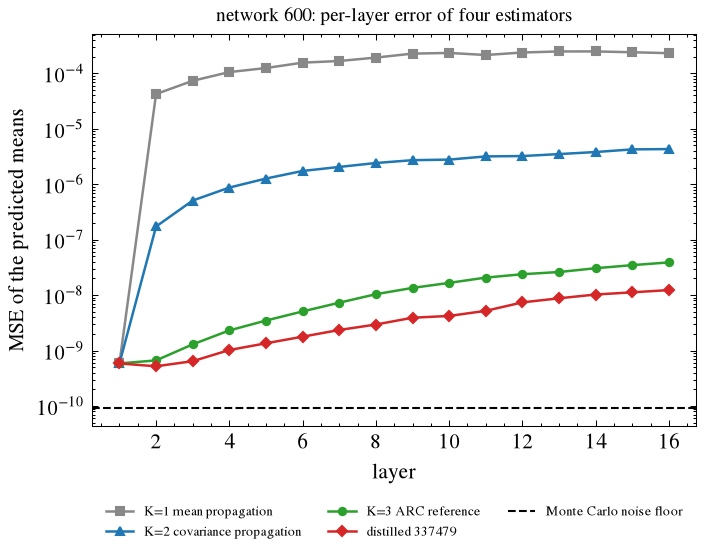

In [6]:
import matplotlib.pyplot as plt, scienceplots  # noqa: F401
plt.style.use(["science", "no-latex"])
fig, ax = plt.subplots(figsize=(5.2, 3.4), dpi=150)
for name, color, marker in zip(results, ["#888888", "#1f77b4", "#2ca02c", "#d62728"], ["s", "^", "o", "D"]):
    ax.plot(layers, mse[name], marker=marker, ms=3.5, lw=1.2, color=color, label=name)
ax.axhline(noise_floor, ls="--", lw=1, color="k", label="Monte Carlo noise floor")
ax.set_yscale("log"); ax.set_xlabel("layer"); ax.set_ylabel("MSE of the predicted means")
ax.set_xticks(layers[1::2]); ax.set_title(f"network 600: per-layer error of four estimators", fontsize=9)
ax.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.savefig("tutorial_mse_per_layer.png", bbox_inches="tight"); plt.show()

## 5. How to read it

- The Gaussian baselines are already wrong by layer 2-3: the ReLU of a Gaussian is skewed, and the skewness (third
  cumulant) shifts every later mean. Each extra cumulant order buys roughly one decade of final-layer MSE.
- Error grows with depth for every method; most of the final-layer error of the best methods is born in layers 8-15.
- The distilled estimator reaches the ~1e-8 level that the graded submissions had (see `RESULTS.md` for the 20-network
  comparison against the graded code), at a FLOP count about five times the graded submissions' because it keeps every
  third-cumulant source dense and uses no fast matrix multiplication. The K=3 reference is cheaper per layer but about
  three times less accurate at the final layer.
- The dashed line is the error of the Monte Carlo targets themselves (`avg_variance / 1e9`); nothing can be measured
  below it with this dataset.

To try another network: take its `mlp_seed`, `all_layer_means` and `avg_variance` from a row of the public dataset
(`aicrowd/arc-whestbench-public-2026`, parquet shards under `data/`, 15-16 networks each) and save them the same way. `README.md` in this folder explains the estimator; `docs/SPEC.md` has its
equations.